# 03 - Baseline time-series simulation

Scenario S1: normal load only. Results come from `results/raw/S1_baseline.pkl` (created by `scripts/run_baseline.py` or `scripts/run_scenarios.py`).

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src.utils.config import load_config
from src.analysis import visualization as viz
viz.apply_style()
config = load_config(ROOT / "config" / "config.yaml")
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)

In [2]:
from src.utils.storage import load_result
from src.analysis.metrics import compute_metrics
from src.simulation.power_flow import energy_balance_residual_kwh
s1 = load_result('S1_baseline'); sim = s1.simulation
print(f'Converged steps: {int(sim.converged.sum())} / {len(sim.converged)}')
print(f'Energy balance residual: {energy_balance_residual_kwh(sim):.2e} kWh')
m = compute_metrics(sim, s1.data.price, config)
pd.Series({k: m[k] for k in ['v_min_pu','v_min_bus','v_max_pu','voltage_violation_bus_steps','voltage_violation_duration_h','buses_with_violation','line_loading_max_pct','trafo_loading_max_pct','peak_import_kw','grid_import_kwh','losses_kwh','losses_pct_of_supply']})

Converged steps: 96 / 96

Energy balance residual: -1.93e-12 kWh

v_min_pu                            0.932949
v_min_bus                          32.000000
v_max_pu                            1.014487
voltage_violation_bus_steps       540.000000
voltage_violation_duration_h       14.000000
buses_with_violation               15.000000
line_loading_max_pct               41.699448
trafo_loading_max_pct              76.087419
peak_import_kw                   3086.699731
grid_import_kwh                 57472.951681
losses_kwh                       2283.514068
losses_pct_of_supply                3.973198
dtype: float64

### Voltage heat map (time x bus)
Undervoltage concentrates at the end of the main feeder (IEEE buses 13-18) and of the lateral 26-33.

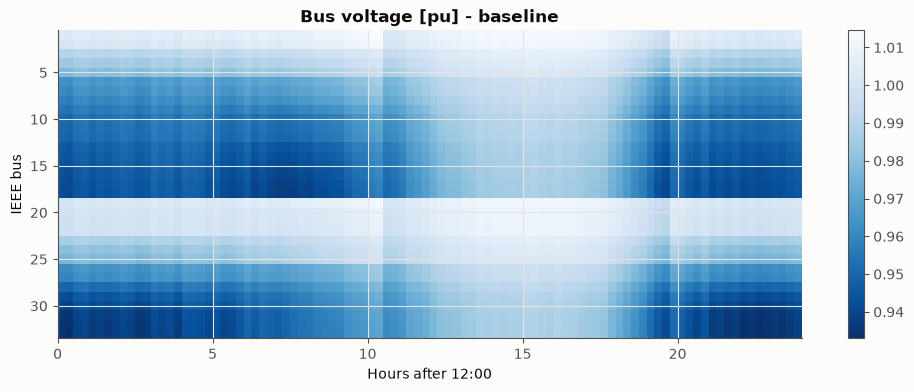

,undervoltage steps
IEEE 17,56
IEEE 18,56
IEEE 16,52
IEEE 15,50
IEEE 32,48
IEEE 33,48
IEEE 14,47
IEEE 31,45
IEEE 30,42
IEEE 13,41


In [3]:
fig, ax = plt.subplots(figsize=(12, 4))
vm = sim.bus_vm_pu
im = ax.imshow(vm.T.values, aspect='auto', cmap='Blues_r', extent=[0, 24, vm.columns.max()+1.5, 0.5])
ax.set(xlabel='Hours after 12:00', ylabel='IEEE bus', title='Bus voltage [pu] - baseline'); fig.colorbar(im, ax=ax); plt.show()
(vm < config['limits']['v_min_pu']).sum().rename(lambda b: f'IEEE {b+1}').loc[lambda s: s > 0].sort_values(ascending=False).to_frame('undervoltage steps')